In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load prepared datasets
df = pd.read_csv("data/intermediate_processing/full_features.csv")

rentals = pd.read_csv(
    "data/intermediate_processing/full_rental_counts.csv",
    parse_dates=["date"]
)

In [2]:
# Keep copies of the original data
# df = df.copy()
# rentals = rentals.copy()

print("=== COMBINED DATASET ===")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\n=== COLUMN NAMES ===")
print(df.columns.tolist())

print("\n=== FIRST 5 ROWS ===")
display(df.head())

print("\n=== DATA TYPES ===")
df.info()

print("\n=== ORIGINAL DATE RANGE ===")
print("First date:", rentals["date"].min())
print("Last date:", rentals["date"].max())


=== COMBINED DATASET ===
Rows: 176359
Columns: 19

=== COLUMN NAMES ===
['start station name', 'month_of_year', 'week_of_year', 'day_of_week', 'hour_of_day', 'is_public_holiday', 'number_of_rentals', 'temperature_2m', 'rain', 'snow_depth', 'snowfall', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high', 'relative_humidity_2m', 'precipitation', 'wind_speed_10m', 'wind_gusts_10m', 'cloud_cover']

=== FIRST 5 ROWS ===


,start station name,month_of_year,week_of_year,day_of_week,hour_of_day,is_public_holiday,number_of_rentals,temperature_2m,rain,snow_depth,snowfall,cloud_cover_low,cloud_cover_mid,cloud_cover_high,relative_humidity_2m,precipitation,wind_speed_10m,wind_gusts_10m,cloud_cover
0,5 Corners Library,1,1,2,8,1,1,1.95,0.0,0.0,0.0,52.0,81.0,0.0,63.509720,0.0,15.328561,24.480000,84.0
1,5 Corners Library,1,1,2,16,1,1,3.70,0.0,0.0,0.0,84.0,52.0,0.0,45.696896,0.0,19.813087,39.600000,84.0
2,5 Corners Library,1,1,3,9,0,1,0.95,0.0,0.0,0.0,0.0,0.0,0.0,72.169720,0.0,13.392774,24.119999,0.0
3,5 Corners Library,1,1,3,12,0,1,6.75,0.0,0.0,0.0,0.0,0.0,13.0,56.080063,0.0,16.641972,30.960001,13.0
4,5 Corners Library,1,1,3,13,0,1,8.35,0.0,0.0,0.0,0.0,0.0,95.0,49.730793,0.0,17.283749,31.319998,95.0



=== DATA TYPES ===
<class 'pandas.DataFrame'>
RangeIndex: 176359 entries, 0 to 176358
Data columns (total 19 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   start station name    176359 non-null  str    
 1   month_of_year         176359 non-null  int64  
 2   week_of_year          176359 non-null  int64  
 3   day_of_week           176359 non-null  int64  
 4   hour_of_day           176359 non-null  int64  
 5   is_public_holiday     176359 non-null  int64  
 6   number_of_rentals     176359 non-null  int64  
 7   temperature_2m        176349 non-null  float64
 8   rain                  176349 non-null  float64
 9   snow_depth            176349 non-null  float64
 10  snowfall              176349 non-null  float64
 11  cloud_cover_low       176349 non-null  float64
 12  cloud_cover_mid       176349 non-null  float64
 13  cloud_cover_high      176349 non-null  float64
 14  relative_humidity_2m  176349 non-null  floa

In [3]:
print("=== MISSING VALUES ===")
missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing %": (df.isna().mean() * 100).round(3)
})

display(missing[missing["Missing Count"] > 0])

print("\n=== DUPLICATE ROWS ===")
print("Exact duplicates:", df.duplicated().sum())

print("\n=== RENTAL COUNT SUMMARY ===")
display(df["number_of_rentals"].describe())

print("\n=== POTENTIAL DATA ISSUES ===")
print("Zero rental rows:",
      (df["number_of_rentals"] == 0).sum())

print("Negative rental rows:",
      (df["number_of_rentals"] < 0).sum())

print("Hour outside 0-23:",
      (~df["hour_of_day"].between(0, 23)).sum())

print("\n=== NUMERICAL SUMMARY ===")
display(df.describe().round(2))


=== MISSING VALUES ===


,Missing Count,Missing %
temperature_2m,10,0.006
rain,10,0.006
snow_depth,10,0.006
snowfall,10,0.006
cloud_cover_low,10,0.006
cloud_cover_mid,10,0.006
cloud_cover_high,10,0.006
relative_humidity_2m,10,0.006
precipitation,10,0.006
wind_speed_10m,10,0.006



=== DUPLICATE ROWS ===
Exact duplicates: 0

=== RENTAL COUNT SUMMARY ===


count    176359.000000
mean          2.230178
std           2.219588
min           1.000000
25%           1.000000
50%           1.000000
75%           3.000000
max          46.000000
Name: number_of_rentals, dtype: float64


=== POTENTIAL DATA ISSUES ===
Zero rental rows: 0
Negative rental rows: 0
Hour outside 0-23: 0

=== NUMERICAL SUMMARY ===


,month_of_year,week_of_year,day_of_week,hour_of_day,is_public_holiday,number_of_rentals,temperature_2m,rain,snow_depth,snowfall,cloud_cover_low,cloud_cover_mid,cloud_cover_high,relative_humidity_2m,precipitation,wind_speed_10m,wind_gusts_10m,cloud_cover
count,176359.00,176359.00,176359.00,176359.00,176359.00,176359.00,176349.00,176349.00,176349.00,176349.00,176349.00,176349.00,176349.00,176349.00,176349.00,176349.00,176349.00,176349.00
mean,5.97,24.57,3.00,13.84,0.02,2.23,14.33,0.08,0.01,0.00,19.24,25.21,36.34,66.40,0.08,14.10,27.38,54.19
std,3.34,14.71,1.98,5.41,0.16,2.22,9.47,0.41,0.04,0.03,33.61,35.17,42.37,18.78,0.41,7.13,12.24,41.30
min,1.00,1.00,0.00,0.00,0.00,1.00,-10.75,0.00,0.00,0.00,0.00,0.00,0.00,21.24,0.00,0.00,2.52,0.00
25%,3.00,11.00,1.00,10.00,0.00,1.00,6.50,0.00,0.00,0.00,0.00,0.00,0.00,51.39,0.00,8.67,18.00,6.00
50%,6.00,25.00,3.00,14.00,0.00,1.00,14.65,0.00,0.00,0.00,0.00,4.00,5.00,66.86,0.00,13.09,25.92,62.00
75%,9.00,37.00,5.00,18.00,0.00,3.00,22.55,0.00,0.00,0.00,20.00,42.00,88.00,82.07,0.00,18.08,34.20,98.00
max,12.00,53.00,6.00,23.00,1.00,46.00,35.95,15.00,0.35,2.38,100.00,100.00,100.00,100.00,15.00,60.36,113.40,100.00


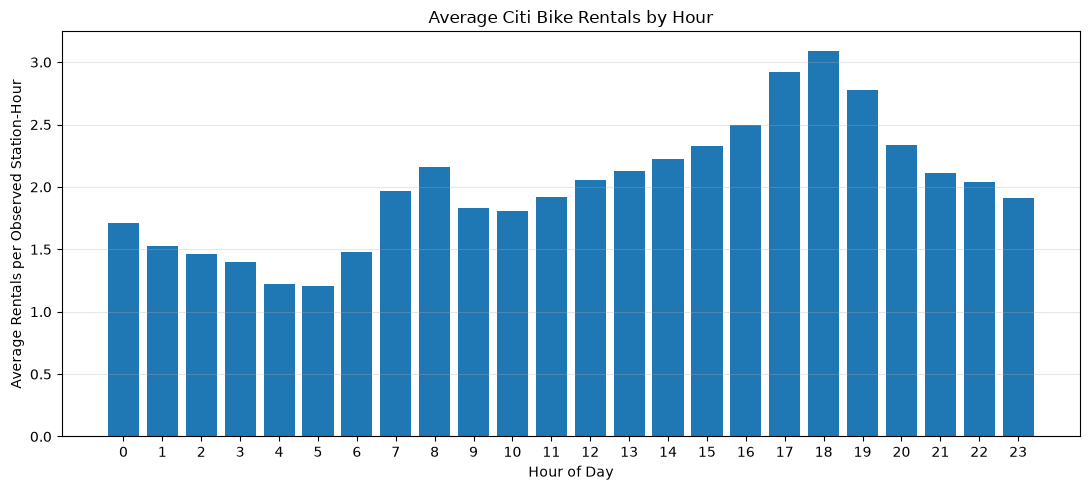

Highest average hour: 18
Lowest average hour: 5


In [4]:
hourly = df.groupby("hour_of_day")["number_of_rentals"].mean()

plt.figure(figsize=(11, 5))
plt.bar(hourly.index, hourly.values)

plt.title("Average Citi Bike Rentals by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Rentals per Observed Station-Hour")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Highest average hour:", hourly.idxmax())
print("Lowest average hour:", hourly.idxmin())


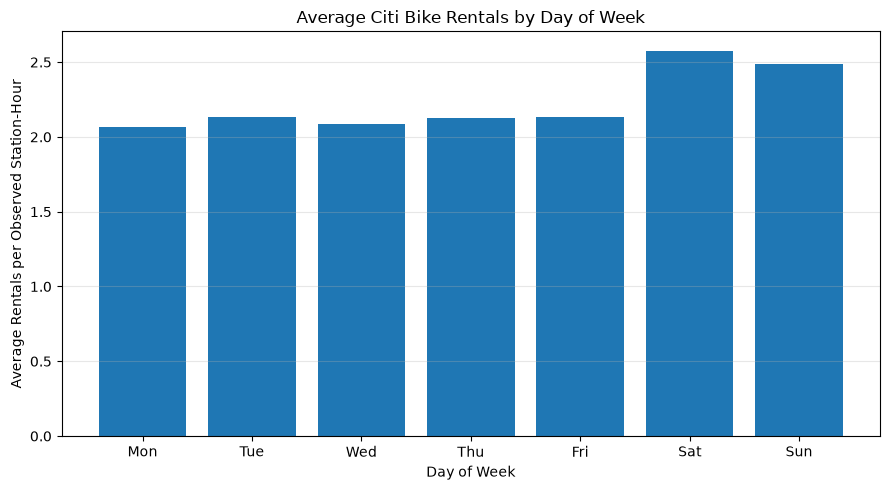

Average rentals by day type:


day_type
Weekday    2.11
Weekend    2.54
Name: number_of_rentals, dtype: float64

In [5]:
# Monday = 0, Sunday = 6
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

daily = df.groupby("day_of_week")["number_of_rentals"].mean()
daily = daily.reindex(range(7))

plt.figure(figsize=(9, 5))
plt.bar(day_names, daily.values)

plt.title("Average Citi Bike Rentals by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Rentals per Observed Station-Hour")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Compare weekdays and weekends
df["day_type"] = np.where(
    df["day_of_week"] >= 5,
    "Weekend",
    "Weekday"
)

day_type_avg = df.groupby("day_type")["number_of_rentals"].mean()

print("Average rentals by day type:")
display(day_type_avg.round(2))


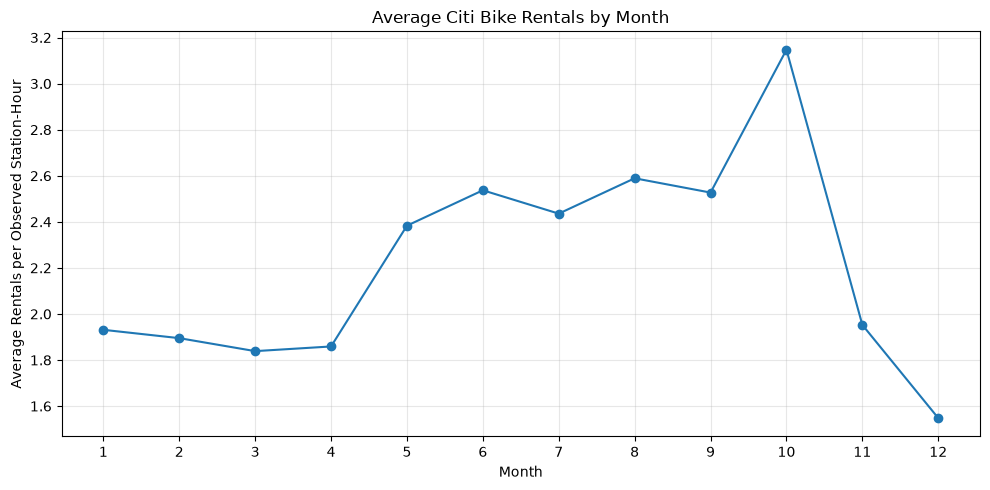

Highest average month: 10
Lowest average month: 12


In [6]:

monthly = df.groupby("month_of_year")["number_of_rentals"].mean()
monthly = monthly.reindex(range(1, 13))

plt.figure(figsize=(10, 5))
plt.plot(monthly.index, monthly.values, marker="o")

plt.title("Average Citi Bike Rentals by Month")
plt.xlabel("Month")
plt.ylabel("Average Rentals per Observed Station-Hour")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Highest average month:", monthly.idxmax())
print("Lowest average month:", monthly.idxmin())


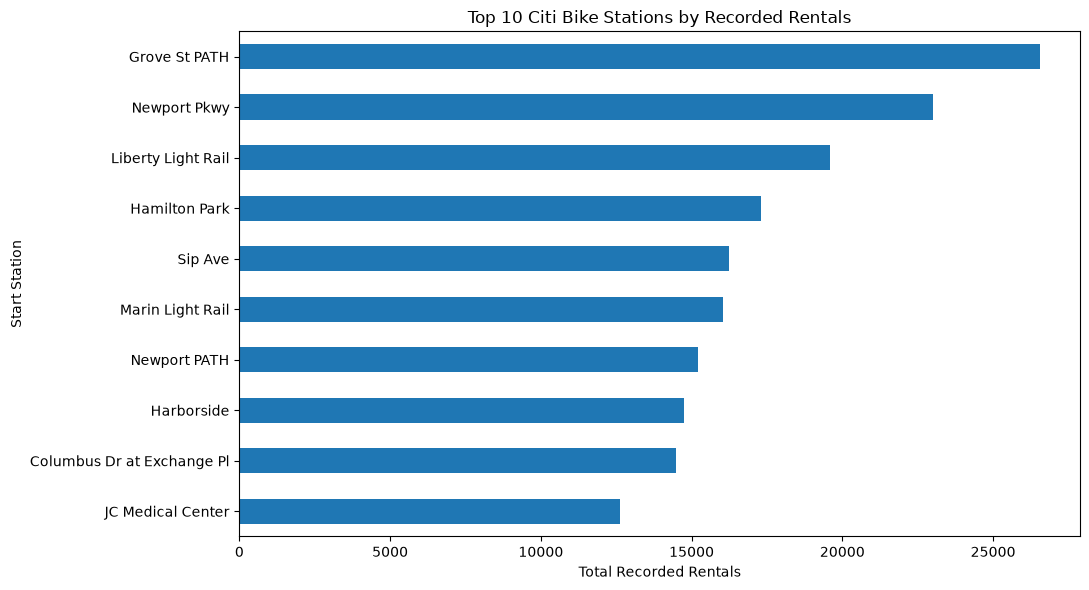

,Total Rentals
start station name,
Grove St PATH,26555
Newport Pkwy,23022
Liberty Light Rail,19580
Hamilton Park,17288
Sip Ave,16228
Marin Light Rail,16057
Newport PATH,15206
Harborside,14733
Columbus Dr at Exchange Pl,14486


In [7]:

station_total = (
    rentals.groupby("start station name")["number_of_rentals"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(11, 6))
station_total.sort_values().plot(kind="barh")

plt.title("Top 10 Citi Bike Stations by Recorded Rentals")
plt.xlabel("Total Recorded Rentals")
plt.ylabel("Start Station")
plt.tight_layout()
plt.show()

display(station_total.to_frame("Total Rentals"))


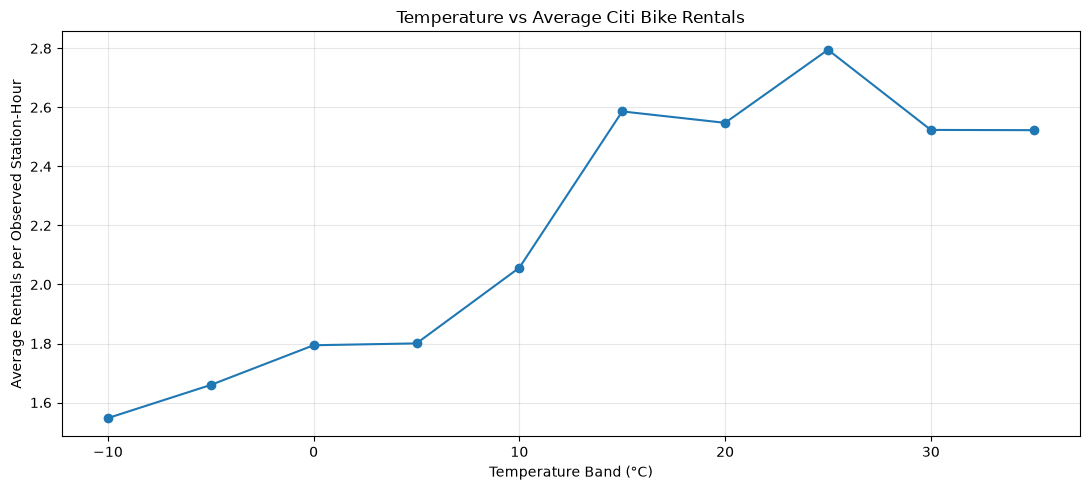

,mean,count
temperature_band,,
-10.0,1.55,1339
-5.0,1.66,10052
0.0,1.79,23932
5.0,1.80,28649
10.0,2.06,25968
15.0,2.59,27079
20.0,2.55,32227
25.0,2.80,22420
30.0,2.52,4416


In [8]:
# Keep rows with valid temperature readings
temp_df = df.dropna(subset=["temperature_2m"]).copy()

# Group temperature into 5-degree Celsius bands
temp_df["temperature_band"] = (
    np.floor(temp_df["temperature_2m"] / 5) * 5
)

temp_demand = (
    temp_df.groupby("temperature_band")["number_of_rentals"]
    .agg(["mean", "count"])
    .sort_index()
)

# Avoid extremely small groups
temp_demand = temp_demand[temp_demand["count"] >= 30]

plt.figure(figsize=(11, 5))
plt.plot(temp_demand.index, temp_demand["mean"], marker="o")

plt.title("Temperature vs Average Citi Bike Rentals")
plt.xlabel("Temperature Band (°C)")
plt.ylabel("Average Rentals per Observed Station-Hour")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(temp_demand.round(2))


,mean,median,count
weather_type,,,
Dry,2.28,1.0,155453
Rainy,1.89,1.0,20896


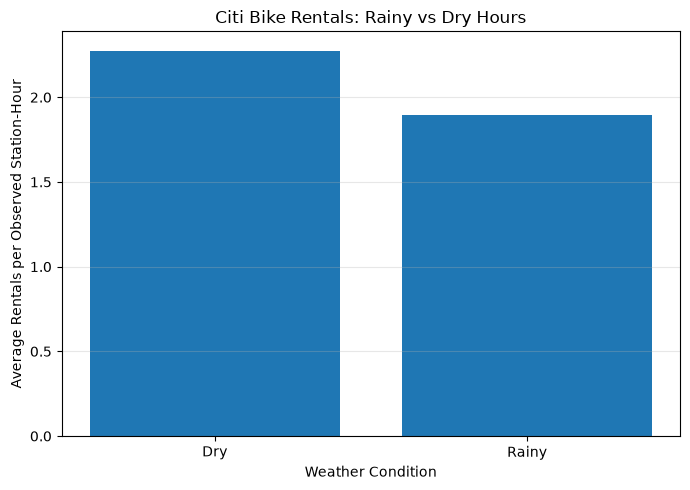

In [9]:

rain_df = df.dropna(subset=["rain"]).copy()

rain_df["weather_type"] = np.where(
    rain_df["rain"] > 0,
    "Rainy",
    "Dry"
)

rain_summary = (
    rain_df.groupby("weather_type")["number_of_rentals"]
    .agg(["mean", "median", "count"])
)

display(rain_summary.round(2))

plt.figure(figsize=(7, 5))
plt.bar(
    rain_summary.index,
    rain_summary["mean"]
)

plt.title("Citi Bike Rentals: Rainy vs Dry Hours")
plt.xlabel("Weather Condition")
plt.ylabel("Average Rentals per Observed Station-Hour")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


,mean,count
snow_condition,,
No Snowfall,2.23,175477
Snowfall,1.39,872


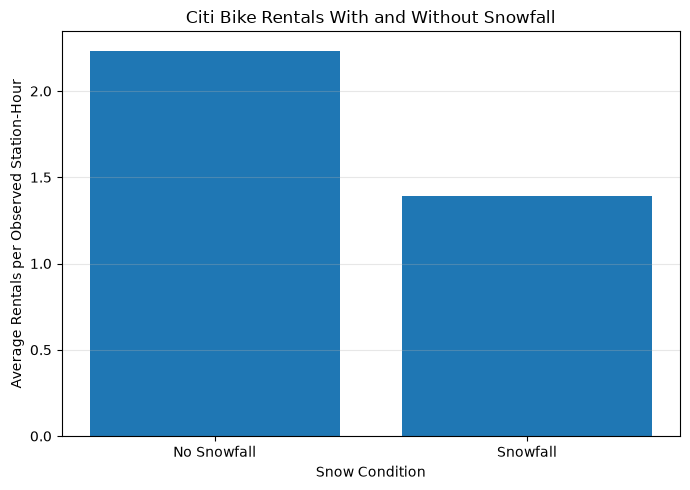

In [10]:

snow_df = df.dropna(subset=["snowfall"]).copy()

snow_df["snow_condition"] = np.where(
    snow_df["snowfall"] > 0,
    "Snowfall",
    "No Snowfall"
)

snow_summary = (
    snow_df.groupby("snow_condition")["number_of_rentals"]
    .agg(["mean", "count"])
)

display(snow_summary.round(2))

plt.figure(figsize=(7, 5))
plt.bar(snow_summary.index, snow_summary["mean"])

plt.title("Citi Bike Rentals With and Without Snowfall")
plt.xlabel("Snow Condition")
plt.ylabel("Average Rentals per Observed Station-Hour")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


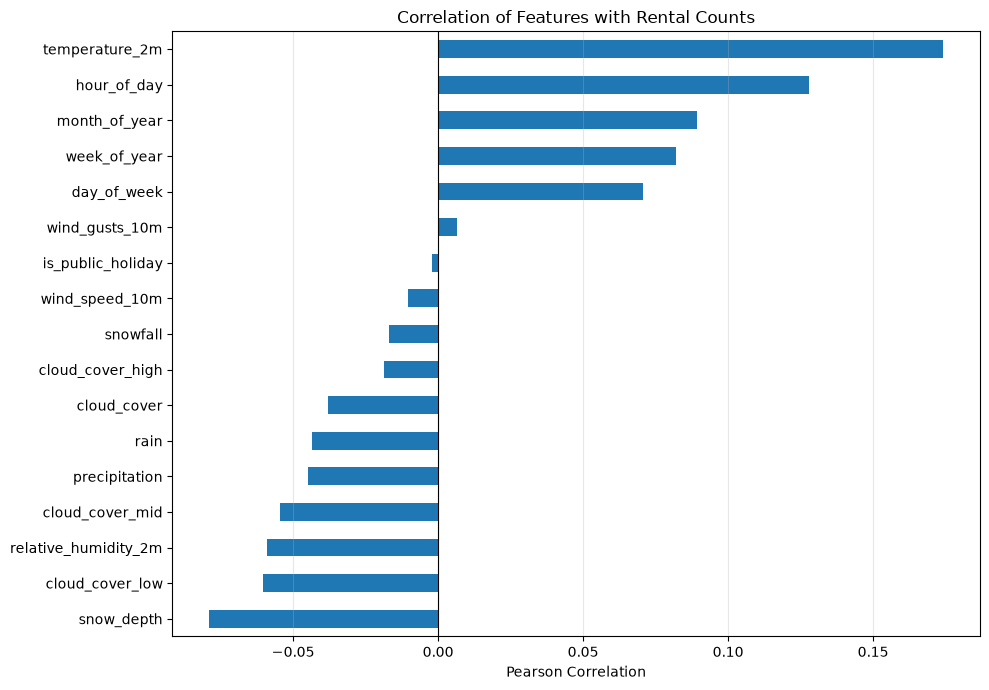

,Correlation with Rentals
snow_depth,-0.079
cloud_cover_low,-0.060
relative_humidity_2m,-0.059
cloud_cover_mid,-0.055
precipitation,-0.045
rain,-0.043
cloud_cover,-0.038
cloud_cover_high,-0.019
snowfall,-0.017
wind_speed_10m,-0.010


In [11]:
# Select only numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlations
correlation = numeric_df.corr()

# Relationship with target variable
target_corr = (
    correlation["number_of_rentals"]
    .drop("number_of_rentals")
    .sort_values()
)

plt.figure(figsize=(10, 7))
target_corr.plot(kind="barh")

plt.title("Correlation of Features with Rental Counts")
plt.xlabel("Pearson Correlation")
plt.axvline(0, color="black", linewidth=0.8)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

display(
    target_corr.to_frame("Correlation with Rentals").round(3)
)


In [12]:
print("=== RENTAL DATA COVERAGE ===")

print("Number of stations:",
      rentals["start station name"].nunique())

print("Number of recorded station-hours:", len(rentals))

print("Zero-rental observations:",
      (rentals["number_of_rentals"] == 0).sum())

print("Unique dates:", rentals["date"].nunique())

print("\n=== DATE COVERAGE ===")
print(rentals.groupby(
    rentals["date"].dt.to_period("M")
)["number_of_rentals"].sum())

print("\n=== STATION-DATE-HOUR DUPLICATES ===")
print(
    rentals.duplicated(
        subset=["start station name", "date", "hour_of_day"]
    ).sum()
)


=== RENTAL DATA COVERAGE ===
Number of stations: 52
Number of recorded station-hours: 176359
Zero-rental observations: 0
Unique dates: 485

=== DATE COVERAGE ===
date
2020-01    26020
2020-02    22962
2020-03    17719
2020-04     9268
2020-05    25077
2020-06    36921
2020-07    38680
2020-08    43267
2020-09    40382
2020-10    43537
2020-11    21275
2020-12    11694
2021-01    11624
2021-02     4725
2021-03    16843
2021-04    23318
Freq: M, Name: number_of_rentals, dtype: int64

=== STATION-DATE-HOUR DUPLICATES ===
0
